# Tensores a fondo: qué pasa por dentro

En `01_tensores_autograd_y_una_neurona` los tensores aparecieron como arreglos de números con una forma. Aquí se abren. Un tensor es un bloque de memoria plano más unos pocos números que dicen cómo leerlo, y con esa idea se explica casi todo lo demás: por qué `view` a veces falla y `reshape` no, por qué modificar un trozo de un tensor modifica el original, por qué el broadcasting no gasta memoria y por qué `[10]` y `[10, 1]` no son lo mismo.

La mayoría de los errores al construir un modelo son de forma, de tipo o de dimensiones. Por eso el notebook termina con un catálogo de esos errores: qué dice el mensaje, qué lo causa y cómo se arregla.

Como hilo conductor usamos al repartidor de `01-red-neuronal-simple`, ahora con más datos por cada entrega.

**Contenido**

1. Preparación
2. Crear tensores a partir de datos
3. Qué hay dentro de un tensor: memoria, forma y strides
4. Cambiar la forma sin mover los datos
5. Indexado y slicing: vistas y copias
6. Tipos de datos y promoción
7. Operaciones matemáticas y agregaciones
8. Broadcasting por dentro
9. Operaciones lógicas y máscaras
10. Leer los errores más comunes
11. Resumen y ejercicios

Ejecuta las celdas en orden: varias dependen de variables definidas más arriba.

## 1. Preparación

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Crear tensores a partir de datos

Los datos casi nunca nacen como tensores. Llegan como listas de Python (leídas de un archivo o de una API) o como arreglos de NumPy (desde pandas, una imagen u otra librería). `torch.tensor` acepta las dos cosas.

### Desde una lista

De cada entrega anotamos la distancia en millas, cuántas paradas intermedias hubo, si llovía (1) o no (0), y cuántos minutos tomó.

In [2]:
entregas = [
    # distancia, paradas, lluvia, tiempo
    [1.0, 0, 0,  7.3],
    [1.5, 1, 0, 12.1],
    [2.0, 0, 1, 15.8],
    [2.5, 2, 0, 20.9],
    [3.0, 1, 1, 24.4],
    [3.5, 0, 0, 19.0],
    [4.0, 2, 1, 32.6],
    [4.5, 1, 0, 27.9],
    [5.0, 3, 1, 39.5],
    [5.5, 0, 0, 29.2],
]

datos = torch.tensor(entregas)
print(datos)
print("forma:", datos.shape, "  dtype:", datos.dtype)

tensor([[ 1.0000,  0.0000,  0.0000,  7.3000],
        [ 1.5000,  1.0000,  0.0000, 12.1000],
        [ 2.0000,  0.0000,  1.0000, 15.8000],
        [ 2.5000,  2.0000,  0.0000, 20.9000],
        [ 3.0000,  1.0000,  1.0000, 24.4000],
        [ 3.5000,  0.0000,  0.0000, 19.0000],
        [ 4.0000,  2.0000,  1.0000, 32.6000],
        [ 4.5000,  1.0000,  0.0000, 27.9000],
        [ 5.0000,  3.0000,  1.0000, 39.5000],
        [ 5.5000,  0.0000,  0.0000, 29.2000]])
forma: torch.Size([10, 4])   dtype: torch.float32


La lista mezcla enteros y decimales, y PyTorch eligió un solo tipo para todo: `float32`. Todos los elementos de un tensor tienen **el mismo dtype**. Si la lista tiene solo enteros el resultado es `int64`, y si tiene solo `True` y `False`, `bool`.

In [3]:
print(torch.tensor([1, 2, 3]).dtype)
print(torch.tensor([1, 2.5, 3]).dtype)
print(torch.tensor([True, False]).dtype)
print(torch.tensor([1, 2, 3], dtype=torch.float32).dtype)   # o se elige a mano

torch.int64
torch.float32
torch.bool
torch.float32


La otra exigencia es que la lista sea **rectangular**. Si a una fila le falta un valor, no hay forma que la describa.

In [4]:
try:
    torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0]])
except ValueError as error:
    print("ValueError:", error)

ValueError: expected sequence of length 3 at dim 1 (got 2)


### Desde NumPy

Hay dos maneras, y la diferencia importa:

- `torch.tensor(arreglo)` **copia** los datos.
- `torch.from_numpy(arreglo)` **comparte** la memoria del arreglo. No duplica nada, que es lo que conviene con datos grandes, pero un cambio en uno se ve en el otro. `torch.as_tensor` hace lo mismo y copia solo si no le queda otra.

In [5]:
arreglo = np.array(entregas)

copia = torch.tensor(arreglo)
compartido = torch.from_numpy(arreglo)

arreglo[0, 0] = 99.0
print("torch.tensor     ->", copia[0, 0].item())
print("torch.from_numpy ->", compartido[0, 0].item())
arreglo[0, 0] = 1.0      # dejamos el arreglo como estaba

print("dtype heredado de NumPy:", compartido.dtype)

torch.tensor     ->

 1.0
torch.from_numpy -> 99.0
dtype heredado de NumPy: torch.float64


En los dos casos el dtype viene de NumPy, que usa `float64` por defecto. Las capas de `torch.nn` trabajan en `float32`, así que lo normal es convertir con `.float()`. Cambiar el dtype **siempre copia**: los números se guardan con otro formato, así que necesitan otro bloque de memoria.

In [6]:
X_numpy = torch.from_numpy(arreglo).float()
print(X_numpy.dtype)
print("¿sigue compartiendo memoria con el arreglo?", np.shares_memory(X_numpy.numpy(), arreglo))

torch.float32
¿sigue compartiendo memoria con el arreglo? False


### Tensores sin datos de origen

Además de `zeros`, `ones`, `rand`, `randn`, `arange` y `linspace` (vistos en el notebook anterior), estas tres aparecen a menudo:

In [7]:
print(torch.full((2, 3), 7.0))
print(torch.eye(3))                    # matriz identidad
print(torch.zeros_like(datos[:2]))     # misma forma y dtype que el tensor que recibe

tensor([[7., 7., 7.],
        [7., 7., 7.]])
tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.]])


## 3. Qué hay dentro de un tensor: memoria, forma y strides

Un tensor de forma `[3, 4]` no guarda una tabla. Guarda sus 12 números **en fila, uno detrás de otro**, en un bloque de memoria que PyTorch llama *storage*. La tabla la arman unos pocos metadatos que dicen cómo recorrer ese bloque:

- **forma** (`shape`): cuántos elementos hay en cada dimensión.
- **strides**: cuántas posiciones del bloque hay que avanzar para dar un paso en cada dimensión.
- **offset** (`storage_offset`): en qué posición del bloque está el primer elemento.

La función `bloque` muestra el storage tal como está en memoria, y `describir` imprime los metadatos.

In [8]:
def bloque(t):
    # Un tensor 1D que recorre el storage completo de t, en orden de memoria
    return torch.empty(0, dtype=t.dtype).set_(t.untyped_storage())


def describir(nombre, t):
    print(f"{nombre:14s} forma={str(tuple(t.shape)):10s} strides={str(t.stride()):10s} "
          f"offset={t.storage_offset():<3d} contiguo={t.is_contiguous()}")


m = torch.arange(12).reshape(3, 4)
print(m)
print("bloque:", bloque(m))
describir("m", m)

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
bloque: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
m              forma=(3, 4)     strides=(4, 1)     offset=0   contiguo=True


Los strides de `m` son `(4, 1)`: para bajar una fila hay que saltar 4 posiciones del bloque, y para avanzar una columna, 1. Entonces el elemento `[i, j]` está en la posición

$$\text{posición} = \text{offset} + i \cdot s_0 + j \cdot s_1$$

y en general, con cualquier número de dimensiones, $\text{offset} + \sum_k i_k \, s_k$. Indexar un tensor es hacer esa cuenta. Lo comprobamos leyendo cada elemento directo del bloque:

In [9]:
def leer(t, indices):
    posicion = t.storage_offset() + sum(i * s for i, s in zip(indices, t.stride()))
    return bloque(t)[posicion]


print("m[1, 2] con la fórmula:", leer(m, (1, 2)).item(), "  con PyTorch:", m[1, 2].item())
coinciden = all(leer(m, (i, j)) == m[i, j] for i in range(3) for j in range(4))
print("¿coinciden los 12 elementos?", coinciden)

m[1, 2] con la fórmula: 6   con PyTorch: 6
¿coinciden los 12 elementos? True


Cuando PyTorch crea un tensor nuevo, guarda los elementos **por filas**: el último índice es el que cambia más rápido. Con ese orden los strides salen solo de la forma. El de la última dimensión es 1, y cada uno de los anteriores es el siguiente multiplicado por el tamaño de la dimensión siguiente.

In [10]:
def strides_por_filas(forma):
    strides = [1]
    for tamano in reversed(forma[1:]):
        strides.insert(0, strides[0] * tamano)
    return tuple(strides)


for forma in [(3, 4), (2, 3, 4), (10,), (64, 3, 28, 28)]:
    print(f"{str(forma):16s} a mano={str(strides_por_filas(forma)):18s} PyTorch={torch.empty(forma).stride()}")

(3, 4)           a mano=(4, 1)             PyTorch=(4, 1)
(2, 3, 4)        a mano=(12, 4, 1)         PyTorch=(12, 4, 1)
(10,)            a mano=(1,)               PyTorch=(1,)
(64, 3, 28, 28)  a mano=(2352, 784, 28, 1) PyTorch=(2352, 784, 28, 1)


En un lote de 64 imágenes a color de 28 × 28 píxeles, avanzar una imagen salta 2352 números (3 × 28 × 28) y avanzar un canal salta 784 (28 × 28).

Un tensor cuyos strides son exactamente esos se llama **contiguo**: leerlo fila por fila es recorrer su bloque en orden, sin saltos. La sección siguiente muestra tensores que no lo son.

## 4. Cambiar la forma sin mover los datos

Como la forma es solo metadata, muchas operaciones de forma no tocan la memoria. Crean un tensor nuevo con otros strides que lee el mismo bloque. A ese tensor se le llama **vista** (*view*). `comparte_memoria` dice si dos tensores leen el mismo bloque.

In [11]:
def comparte_memoria(a, b):
    return a.untyped_storage().data_ptr() == b.untyped_storage().data_ptr()


v = m.view(2, 6)
describir("m", m)
describir("m.view(2, 6)", v)
print("¿comparten memoria?", comparte_memoria(m, v))

v[0, 0] = 100
print("m[0, 0] después de modificar v:", m[0, 0].item())
m[0, 0] = 0

m              forma=(3, 4)     strides=(4, 1)     offset=0   contiguo=True
m.view(2, 6)   forma=(2, 6)     strides=(6, 1)     offset=0   contiguo=True
¿comparten memoria? True
m[0, 0] después de modificar v: 100


### La transpuesta

Transponer tampoco mueve ningún número: intercambia los strides.

In [12]:
mt = m.t()
describir("m", m)
describir("m.t()", mt)
print("¿comparten memoria?", comparte_memoria(m, mt))

m              forma=(3, 4)     strides=(4, 1)     offset=0   contiguo=True
m.t()          forma=(4, 3)     strides=(1, 4)     offset=0   contiguo=False
¿comparten memoria? True


En el dibujo, el color de cada celda es su posición en el bloque, calculada con la fórmula de la sección 3.

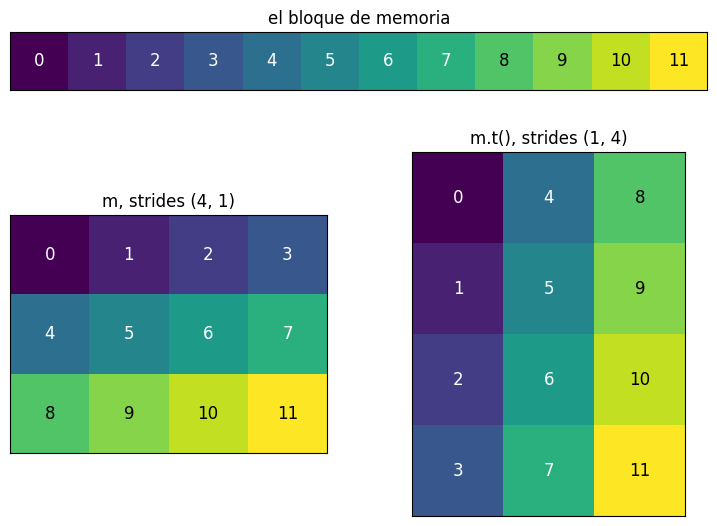

In [13]:
def posiciones(t):
    # Posición en el bloque de cada elemento de un tensor 2D
    filas, columnas = t.shape
    return torch.tensor([[t.storage_offset() + i * t.stride(0) + j * t.stride(1)
                          for j in range(columnas)] for i in range(filas)])


def dibujar(eje, valores, colores, titulo):
    eje.imshow(colores, cmap="viridis", vmin=0, vmax=11)
    for (i, j), valor in np.ndenumerate(valores.numpy()):
        color_texto = "black" if colores[i, j] >= 8 else "white"
        eje.text(j, i, valor, ha="center", va="center", color=color_texto, fontsize=12)
    eje.set_xticks([])
    eje.set_yticks([])
    eje.set_title(titulo)


fig, ejes = plt.subplot_mosaic([["bloque", "bloque"], ["m", "mt"]],
                               figsize=(9, 6.5), height_ratios=[1, 4])
dibujar(ejes["bloque"], bloque(m).unsqueeze(0), torch.arange(12).unsqueeze(0), "el bloque de memoria")
dibujar(ejes["m"], m, posiciones(m), "m, strides (4, 1)")
dibujar(ejes["mt"], mt, posiciones(mt), "m.t(), strides (1, 4)")
plt.show()

En `m` los colores avanzan en orden al leer fila por fila: el tensor es contiguo. En `m.t()` los mismos 12 números se leen saltando de 4 en 4, porque cada fila de la transpuesta es una columna de `m`. La transpuesta no es contigua.

### `view` contra `reshape`

`view` solo cambia metadata, así que funciona únicamente si la forma pedida se puede describir con strides sobre el bloque tal como está. Para aplanar `m.t()` habría que leer el bloque en el orden 0, 4, 8, 1, 5, 9, ..., y ese orden no se consigue con un único stride.

In [14]:
try:
    mt.view(12)
except RuntimeError as error:
    print("RuntimeError:", error)

RuntimeError: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.


`reshape` hace lo mismo que `view` cuando se puede, y cuando no, copia los números a un bloque nuevo en el orden correcto. `.contiguous()` hace esa copia de forma explícita.

In [15]:
plano = m.reshape(12)
plano_t = mt.reshape(12)
print("m.reshape(12)     ", plano, "  ¿vista?", comparte_memoria(m, plano))
print("m.t().reshape(12) ", plano_t, "  ¿vista?", comparte_memoria(m, plano_t))

describir("m.t().contiguous()", mt.contiguous())

m.reshape(12)      tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])   ¿vista? True
m.t().reshape(12)  tensor([ 0,  4,  8,  1,  5,  9,  2,  6, 10,  3,  7, 11])   ¿vista? False
m.t().contiguous() forma=(4, 3)     strides=(3, 1)     offset=0   contiguo=True


La consecuencia práctica: con `reshape` no se sabe de antemano si el resultado comparte memoria con el original. Si después vas a modificar uno de los dos, no dependas de eso y saca una copia con `.clone()`.

`permute`, que reordena cualquier número de dimensiones, funciona igual que la transpuesta: reordena los strides y deja el bloque intacto.

### Las formas que pide un modelo

`unsqueeze` y `squeeze` también son vistas: agregar o quitar una dimensión de tamaño 1 no cambia qué números hay ni dónde están, solo cómo se indexan. `flatten` se comporta como `reshape`, una vista cuando se puede. Estos son los casos que aparecen al preparar datos:

In [16]:
tiempos = datos[:, 3]
print("tiempos                  ", tiempos.shape)
print("como columna [N, 1]      ", tiempos.unsqueeze(1).shape)      # la forma de la salida de nn.Linear(…, 1)
print("un solo ejemplo [1, 3]   ", datos[0, :3].unsqueeze(0).shape)  # una capa espera un lote, aunque sea de uno

imagenes = torch.rand(64, 28, 28)                                    # 64 imágenes en escala de grises
print("imágenes aplanadas       ", imagenes.flatten(start_dim=1).shape)  # [64, 784] para una capa densa

foto = torch.rand(480, 640, 3)                                       # alto, ancho, canal: como la entregan NumPy o PIL
print("canal primero            ", foto.permute(2, 0, 1).shape)     # PyTorch espera canal, alto, ancho

tiempos                   torch.Size([10])
como columna [N, 1]       torch.Size([10, 1])
un solo ejemplo [1, 3]    torch.Size([1, 3])
imágenes aplanadas        torch.Size([64, 784])
canal primero             torch.Size([3, 480, 640])


## 5. Indexado y slicing: vistas y copias

### Indexado básico: siempre una vista

Con enteros y rangos (`a:b:paso`), el resultado también es metadata nueva sobre el mismo bloque: otro offset y otros strides.

In [17]:
describir("m", m)
describir("m[1]", m[1])
describir("m[:, 2]", m[:, 2])
describir("m[:, ::2]", m[:, ::2])
describir("m[1:, 1:3]", m[1:, 1:3])
print("¿comparten memoria con m?", all(comparte_memoria(m, t) for t in [m[1], m[:, 2], m[:, ::2], m[1:, 1:3]]))

m              forma=(3, 4)     strides=(4, 1)     offset=0   contiguo=True
m[1]           forma=(4,)       strides=(1,)       offset=4   contiguo=True
m[:, 2]        forma=(3,)       strides=(4,)       offset=2   contiguo=False
m[:, ::2]      forma=(3, 2)     strides=(4, 2)     offset=0   contiguo=False
m[1:, 1:3]     forma=(2, 2)     strides=(4, 1)     offset=5   contiguo=False
¿comparten memoria con m? True


`m[1]` empieza en la posición 4 del bloque. `m[:, 2]` empieza en la 2 y avanza de 4 en 4. `m[:, ::2]` toma una columna sí y una no, con stride 2. Ninguno copió nada.

Eso tiene una consecuencia: **escribir sobre un slice escribe sobre el original**. Por ejemplo, pasar las distancias a kilómetros sobre una copia de la tabla:

In [18]:
tabla = datos.clone()
distancias = tabla[:, 0]      # vista de la primera columna
distancias *= 1.609           # multiplicación en el lugar

print(tabla[:3])              # la tabla también quedó en kilómetros

tensor([[ 1.6090,  0.0000,  0.0000,  7.3000],
        [ 2.4135,  1.0000,  0.0000, 12.1000],
        [ 3.2180,  0.0000,  1.0000, 15.8000]])


`distancias * 1.609` no tendría el problema, porque crea un tensor nuevo. El problema está en las operaciones que escriben **en el lugar**: `*=`, `+=`, la asignación `t[...] = valor` y los métodos que terminan en guion bajo (`add_`, `zero_`, `clamp_`). Si vas a modificar un trozo y quieres conservar el original, sácalo con `.clone()`.

### Indexado avanzado: siempre una copia

Si el índice es una lista de posiciones o una máscara booleana, los elementos elegidos en general no están a una distancia fija entre sí, y no hay strides que los describan. PyTorch copia, aunque en algún caso particular se pudiera evitar.

In [19]:
filas_elegidas = m[[0, 2]]
pares = m[m % 2 == 0]
print(filas_elegidas, "  ¿vista?", comparte_memoria(m, filas_elegidas))
print(pares, "  ¿vista?", comparte_memoria(m, pares))

tensor([[ 0,  1,  2,  3],
        [ 8,  9, 10, 11]])   ¿vista? False
tensor([ 0,  2,  4,  6,  8, 10])   ¿vista? False


Ojo con la asimetría: **leer** con un índice avanzado copia, pero **asignar** con uno escribe en el original. `m[m > 9] = 0` cambia `m`.

### Separar entradas y etiquetas

Con la tabla de entregas, las entradas del modelo son las tres primeras columnas y la etiqueta es el tiempo.

In [20]:
X = datos[:, :3]        # distancia, paradas, lluvia
y = datos[:, 3]         # tiempo
y_col = datos[:, 3:]    # tiempo, conservando la dimensión

print("X     ", X.shape)
print("y     ", y.shape)
print("y_col ", y_col.shape)

X      torch.Size([10, 3])
y      torch.Size([10])
y_col  torch.Size([10, 1])


Un índice entero **elimina** la dimensión que indexa. Un rango la **conserva**, aunque tenga un solo elemento. `datos[:, 3]` da `[10]` y `datos[:, 3:]` da `[10, 1]`. Esa diferencia causa un error silencioso que aparece en la sección 8.

Dos atajos más: `...` reemplaza todas las dimensiones que no se nombran, y `None` agrega una dimensión de tamaño 1, como `unsqueeze`.

In [21]:
lote = torch.rand(64, 3, 28, 28)
print(lote[..., 0].shape)     # igual que lote[:, :, :, 0]
print(lote[:, None].shape)    # igual que lote.unsqueeze(1)

torch.Size([64, 3, 28])
torch.Size([64, 1, 3, 28, 28])


## 6. Tipos de datos y promoción

El dtype decide cuántos bytes ocupa cada elemento y qué valores puede representar.

In [22]:
for dtype in [torch.bool, torch.uint8, torch.int32, torch.int64, torch.float16, torch.float32, torch.float64]:
    t = torch.zeros(1000, 1000, dtype=dtype)
    megabytes = t.nelement() * t.element_size() / 1e6
    print(f"{str(dtype):14s} {t.element_size()} bytes por elemento    un millón de elementos: {megabytes:.0f} MB")

torch.bool     1 bytes por elemento    un millón de elementos: 1 MB
torch.uint8    1 bytes por elemento    un millón de elementos: 1 MB
torch.int32    4 bytes por elemento    un millón de elementos: 4 MB


torch.int64    8 bytes por elemento    un millón de elementos: 8 MB
torch.float16  2 bytes por elemento    un millón de elementos: 2 MB
torch.float32  4 bytes por elemento    un millón de elementos: 4 MB
torch.float64  8 bytes por elemento    un millón de elementos: 8 MB


- `float32` es el estándar para entrenar: precisión suficiente con la mitad de memoria que `float64`.
- `int64` es el tipo de los índices y de las etiquetas de clase. `nn.CrossEntropyLoss` lo exige cuando la etiqueta es el número de la clase.
- `uint8` es como suelen llegar las imágenes: un entero de 0 a 255 por píxel.
- `bool` es el resultado de las comparaciones (sección 9).

### Qué dtype tiene el resultado

Al operar tensores de tipos distintos, PyTorch elige un tipo común, y no es siempre el más grande:

1. Las categorías se ordenan `bool < enteros < decimales`, y el resultado toma la más alta.
2. Dentro de una misma categoría, un número de Python o un tensor de 0 dimensiones no agranda el tipo del tensor con dimensiones: `int32 + 5` sigue siendo `int32`.
3. Entre tensores con dimensiones de la misma categoría, gana el más grande: `float32 + float64` da `float64`.

In [23]:
enteros = torch.tensor([1, 2, 3])            # int64
decimales = torch.tensor([0.5, 0.5, 0.5])    # float32

print("int64 + float32               ", (enteros + decimales).dtype)
print("int64 + 1.5                   ", (enteros + 1.5).dtype)
print("int32 + 5                     ", (enteros.int() + 5).dtype)
print("float32 + float64 (vector)    ", (decimales + decimales.double()).dtype)
print("float32 + float64 (0 dims)    ", (decimales + torch.tensor(1.0, dtype=torch.float64)).dtype)
print("torch.result_type lo anticipa:", torch.result_type(enteros, decimales))

int64 + float32                torch.float32


int64 + 1.5                    torch.float32
int32 + 5                      torch.int32
float32 + float64 (vector)     torch.float64
float32 + float64 (0 dims)     torch.float32
torch.result_type lo anticipa: torch.float32


La división `/` siempre da decimales, aunque los dos operandos sean enteros. Para la división entera está `//`, que redondea hacia abajo, también con negativos.

In [24]:
print(enteros / 2)
print(torch.tensor([7, -7]) // 2)     # -7 // 2 = -4, no -3

tensor([0.5000, 1.0000, 1.5000])
tensor([ 3, -4])


### Los enteros dan la vuelta

Un `uint8` solo representa de 0 a 255. Si una cuenta se pasa, el resultado **da la vuelta** sin ningún aviso.

In [25]:
pixeles = torch.tensor([100, 200, 250], dtype=torch.uint8)
print("pixeles + 10 ", pixeles + 10)      # 250 + 10 = 260, y 260 - 256 = 4
print("pixeles * 2  ", pixeles * 2)       # 200 * 2 = 400, y 400 - 256 = 144
print("bien         ", pixeles.float() / 255)

pixeles + 10  tensor([110, 210,   4], dtype=torch.uint8)
pixeles * 2   tensor([200, 144, 244], dtype=torch.uint8)
bien          tensor([0.3922, 0.7843, 0.9804])


Por eso las imágenes se convierten a `float32` (y casi siempre se dividen por 255) antes de hacer cualquier cuenta con ellas.

## 7. Operaciones matemáticas y agregaciones

Las operaciones elemento a elemento (`+`, `*`, `**`) se vieron en el notebook anterior, y funciones como `torch.exp`, `torch.log`, `torch.sqrt`, `torch.abs` o `torch.clamp` se comportan igual: se aplican a cada elemento y conservan la forma. Aquí nos detenemos en las que cambian la forma: las agregaciones.

### El argumento `dim`

`dim` dice **qué dimensión desaparece**. En la tabla `X` de forma `[10, 3]`, `dim=0` colapsa las 10 entregas y deja un valor por columna.

In [26]:
print("media por columna  ", X.mean(dim=0))
print("suma por fila      ", X.sum(dim=1).shape)

mas_larga = y.argmax()
print(f"la entrega más larga es la {mas_larga.item()}: {datos[mas_larga].tolist()}")

maximos = X.max(dim=0)               # con dim, max devuelve los valores y sus posiciones
print("máximo por columna ", maximos.values, " en las filas", maximos.indices)

media por columna   tensor([3.2500, 1.0000, 0.4000])
suma por fila       torch.Size([10])
la entrega más larga es la 8: [5.0, 3.0, 1.0, 39.5]
máximo por columna  tensor([5.5000, 3.0000, 1.0000])  en las filas tensor([9, 8, 2])


### `keepdim=True`

Una agregación con `dim` elimina esa dimensión. `keepdim=True` la deja con tamaño 1, y eso es lo que hace falta cuando el resultado se va a combinar con el tensor original. Por ejemplo, para que cada fila sume 1 (lo que hace softmax al final):

In [27]:
puntajes = torch.rand(4, 3)

print("sin keepdim:", puntajes.sum(dim=1).shape)
print("con keepdim:", puntajes.sum(dim=1, keepdim=True).shape)

try:
    puntajes / puntajes.sum(dim=1)
except RuntimeError as error:
    print("RuntimeError:", error)

proporciones = puntajes / puntajes.sum(dim=1, keepdim=True)
print("cada fila suma:", proporciones.sum(dim=1))

sin keepdim: torch.Size([4])
con keepdim: torch.Size([4, 1])
RuntimeError: The size of tensor a (3) must match the size of tensor b (4) at non-singleton dimension 1
cada fila suma: tensor([1.0000, 1.0000, 1.0000, 1.0000])


`[4, 3]` dividido por `[4]` falla, porque el broadcasting compara de derecha a izquierda y alinea el 4 con el 3. Con `[4, 1]` el 1 se estira a lo largo de cada fila. Si la matriz fuera cuadrada, la versión sin `keepdim` no fallaría y daría un resultado incorrecto (ejercicio 5).

### Una capa lineal es un producto matricial

Con estas piezas se puede escribir a mano lo que hace `nn.Linear`: $\hat{y} = X W^\top + b$. `W` tiene forma `[salidas, entradas]` y `b` tiene una componente por salida, que el broadcasting suma a cada fila.

In [28]:
torch.manual_seed(0)
capa = nn.Linear(3, 1)

with torch.no_grad():
    salida = capa(X)
    a_mano = X @ capa.weight.T + capa.bias

print(f"X {tuple(X.shape)} @ W.T {tuple(capa.weight.T.shape)} + b {tuple(capa.bias.shape)} -> {tuple(a_mano.shape)}")
print("¿coincide con nn.Linear?", torch.allclose(salida, a_mano))

X (10, 3) @ W.T (3, 1) + b (1,) -> (10, 1)
¿coincide con nn.Linear? True


## 8. Broadcasting por dentro

La regla se vio en el notebook anterior: se comparan las formas de derecha a izquierda, y dos tamaños son compatibles si son iguales o si uno es 1 (una dimensión que falta cuenta como 1). Escrita a mano y comparada con `torch.broadcast_shapes`:

In [29]:
def forma_broadcast(a, b):
    resultado = []
    for k in range(1, max(len(a), len(b)) + 1):
        ta = a[-k] if k <= len(a) else 1
        tb = b[-k] if k <= len(b) else 1
        if ta != tb and 1 not in (ta, tb):
            raise ValueError(f"{ta} y {tb} no son compatibles")
        resultado.insert(0, max(ta, tb))
    return tuple(resultado)


def con_pytorch(a, b):
    try:
        return tuple(torch.broadcast_shapes(a, b))
    except RuntimeError:
        return "error"


def a_mano(a, b):
    try:
        return forma_broadcast(a, b)
    except ValueError:
        return "error"


for a, b in [((10, 3), (3,)), ((3, 1), (1, 4)), ((10, 1), (10,)), ((64, 3, 28, 28), (3, 1, 1)), ((4, 3), (4,))]:
    print(f"{str(a):16s} con {str(b):10s} a mano={str(a_mano(a, b)):18s} PyTorch={con_pytorch(a, b)}")

(10, 3)          con (3,)       a mano=(10, 3)            PyTorch=(10, 3)
(3, 1)           con (1, 4)     a mano=(3, 4)             PyTorch=(3, 4)
(10, 1)          con (10,)      a mano=(10, 10)           PyTorch=(10, 10)
(64, 3, 28, 28)  con (3, 1, 1)  a mano=(64, 3, 28, 28)    PyTorch=(64, 3, 28, 28)
(4, 3)           con (4,)       a mano=error              PyTorch=error


### Estirar sin copiar

Lo nuevo es cómo lo hace. Estirar un tensor no copia sus números: crea una vista con **stride 0** en la dimensión estirada. Avanzar en esa dimensión no avanza en el bloque, así que todas las filas leen los mismos números.

In [30]:
fila = torch.tensor([10, 20, 30, 40])
estirada = fila.expand(3, 4)

print(estirada)
describir("fila", fila)
describir("estirada", estirada)
print("¿comparten memoria?", comparte_memoria(fila, estirada))

tensor([[10, 20, 30, 40],
        [10, 20, 30, 40],
        [10, 20, 30, 40]])
fila           forma=(4,)       strides=(1,)       offset=0   contiguo=True
estirada       forma=(3, 4)     strides=(0, 1)     offset=0   contiguo=False
¿comparten memoria? True


Al hacer `matriz + fila`, PyTorch estira `fila` así y después opera elemento a elemento. Por eso sumar un vector a una matriz de un millón de filas no crea un millón de copias del vector.

### Normalizar las columnas

El uso más común en la preparación de datos: restar a cada columna su media y dividir por su desviación. `X` es `[10, 3]` y las medias son `[3]`, así que cada columna se combina con su propia media.

In [31]:
X_norm = (X - X.mean(dim=0)) / X.std(dim=0)
print("medias     ", X_norm.mean(dim=0))
print("desviación ", X_norm.std(dim=0))

medias      tensor([0., 0., 0.])
desviación  tensor([1., 1., 1.])


### El error silencioso: `[10, 1]` contra `[10]`

La salida de `nn.Linear(3, 1)` tiene forma `[10, 1]`. La etiqueta `y` que sacamos con `datos[:, 3]` tiene forma `[10]`. Restarlas no da error:

In [32]:
with torch.no_grad():
    y_pred = capa(X)

print("y_pred - y      ", (y_pred - y).shape)
print("y_pred - y_col  ", (y_pred - y_col).shape)

y_pred - y       torch.Size([10, 10])
y_pred - y_col   torch.Size([10, 1])


Comparando de derecha a izquierda, el 1 de `y_pred` se estira a 10 columnas, y a `y` le falta una dimensión, que cuenta como 1 y se estira a 10 filas. El resultado es la tabla de **todas** las diferencias entre cada predicción y cada etiqueta: 100 números en vez de 10.

La pérdida sigue siendo un número y el entrenamiento corre sin quejarse. Pero lo que minimiza es el error de cada predicción contra todas las etiquetas a la vez, y eso se logra prediciendo lo mismo para todas: la media. Lo comprobamos entrenando dos veces el mismo modelo:

In [33]:
def entrenar(etiquetas, pasos=500):
    torch.manual_seed(0)
    modelo = nn.Linear(3, 1)
    optimizador = torch.optim.SGD(modelo.parameters(), lr=0.05)
    for _ in range(pasos):
        perdida = ((modelo(X_norm) - etiquetas) ** 2).mean()
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
    with torch.no_grad():
        return modelo(X_norm).squeeze(1)


print("tiempos reales     ", y)
print("etiqueta [10, 1]   ", entrenar(y_col).round(decimals=1))
print("etiqueta [10]      ", entrenar(y).round(decimals=1))
print("media de los tiempos", y.mean().item())

tiempos reales      tensor([ 7.3000, 12.1000, 15.8000, 20.9000, 24.4000, 19.0000, 32.6000, 27.9000,
        39.5000, 29.2000])


etiqueta [10, 1]    tensor([ 7.1000, 12.6000, 16.0000, 20.6000, 24.1000, 19.4000, 32.1000, 27.4000,
        40.1000, 29.3000])


etiqueta [10]       tensor([22.9000, 22.9000, 22.9000, 22.9000, 22.9000, 22.9000, 22.9000, 22.9000,
        22.9000, 22.9000])
media de los tiempos 22.869998931884766


Con la etiqueta en `[10, 1]` el modelo sigue los tiempos reales. Con `[10]` predice la media para todas las entregas.

`nn.MSELoss` por lo menos avisa:

In [34]:
import warnings

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    nn.MSELoss()(y_pred, y)

print(f"{avisos[0].category.__name__}: {avisos[0].message}")

Si la pérdida se escribe a mano no hay aviso. La defensa es mirar las formas: antes de calcular la pérdida, la predicción y la etiqueta deben tener **exactamente la misma forma**. Un `assert y_pred.shape == y_col.shape` en el ciclo de entrenamiento cuesta una línea.

## 9. Operaciones lógicas y máscaras

Una comparación entre tensores se hace elemento a elemento y devuelve un tensor `bool` de la misma forma. Las máscaras se combinan con `&` (y), `|` (o) y `~` (no).

In [35]:
tiempos = datos[:, 3]
lluvia = datos[:, 2] == 1
tarde = tiempos > 30

print("llovió ", lluvia)
print("tarde  ", tarde)

llovió  tensor([False, False,  True, False,  True, False,  True, False,  True, False])
tarde   tensor([False, False, False, False, False, False,  True, False,  True, False])


Como `True` vale 1 y `False` vale 0, sumar una máscara cuenta y promediarla da una proporción. Usada como índice, filtra filas.

In [36]:
print("entregas tarde        ", tarde.sum().item())
print("proporción tarde      ", round(tarde.float().mean().item(), 2))
print("tarde y con lluvia    ", (tarde & lluvia).sum().item())
print("a tiempo y sin lluvia ", (~tarde & ~lluvia).sum().item())
print("¿alguna tarde?        ", tarde.any().item(), "   ¿todas?", tarde.all().item())

print(f"\ntiempo medio con lluvia: {tiempos[lluvia].mean():.1f} min")
print(f"tiempo medio sin lluvia: {tiempos[~lluvia].mean():.1f} min")
print("\nentregas tarde:\n", datos[tarde])

entregas tarde         2
proporción tarde       0.2
tarde y con lluvia     2
a tiempo y sin lluvia  6
¿alguna tarde?         True    ¿todas? False

tiempo medio con lluvia: 28.1 min
tiempo medio sin lluvia: 19.4 min

entregas tarde:
 tensor([[ 4.0000,  2.0000,  1.0000, 32.6000],
        [ 5.0000,  3.0000,  1.0000, 39.5000]])


### Dos trampas de Python

`and`, `or`, `not` e `if` necesitan **un solo** valor de verdad, y un tensor de varios elementos no lo tiene. Para combinar máscaras se usan `&`, `|` y `~`, y para reducir una máscara a un valor, `.any()` o `.all()`.

In [37]:
try:
    tarde and lluvia
except RuntimeError as error:
    print("RuntimeError:", error)

RuntimeError: Boolean value of Tensor with more than one value is ambiguous


La segunda trampa no da error. En Python `&` tiene **más prioridad** que `>`, así que sin paréntesis la expresión se agrupa de otra forma:

In [38]:
mal = tiempos > 20 & lluvia        # se lee como tiempos > (20 & lluvia)
bien = (tiempos > 20) & lluvia

print("sin paréntesis:", mal.sum().item(), "entregas")
print("con paréntesis:", bien.sum().item(), "entregas")

sin paréntesis: 10 entregas
con paréntesis: 3 entregas


`20 & lluvia` hace un *y* bit a bit entre 20 y cada 0 o 1. Como 20 es par, da 0 en todos los casos, y la condición termina siendo `tiempos > 0`, que es cierta para todas. Cada comparación va entre paréntesis.

### `torch.where`: elegir elemento a elemento

`torch.where(condicion, a, b)` toma de `a` donde la condición es cierta y de `b` donde no. ReLU es exactamente eso:

In [39]:
z = torch.tensor([-2.0, -0.5, 0.0, 1.5, 3.0])
print(torch.where(z > 0, z, 0.0))
print(torch.relu(z))

tensor([0.0000, 0.0000, 0.0000, 1.5000, 3.0000])
tensor([0.0000, 0.0000, 0.0000, 1.5000, 3.0000])


### Exactitud de un clasificador

La métrica más usada en clasificación también es una comparación: la proporción de predicciones que coinciden con la etiqueta.

In [40]:
probabilidades = torch.tensor([0.9, 0.2, 0.6, 0.4, 0.8])
etiquetas = torch.tensor([1, 0, 0, 0, 1])

predicciones = (probabilidades > 0.5).long()
print("predicciones", predicciones)
print("exactitud   ", round((predicciones == etiquetas).float().mean().item(), 2))

predicciones tensor([1, 0, 1, 0, 1])
exactitud    0.8


### Comparar decimales

`==` exige igualdad exacta, y los decimales arrastran errores de redondeo. Sumar 0.1 diez veces no da exactamente 1, aunque al imprimirlo lo parezca. Para decimales se usa `torch.isclose` (elemento a elemento) o `torch.allclose` (todo el tensor), que aceptan una tolerancia.

In [41]:
total = torch.full((10,), 0.1).sum()
print(total, "->", total.item())
print("total == 1        ", (total == 1.0).item())
print("isclose(total, 1) ", torch.isclose(total, torch.tensor(1.0)).item())

tensor(1.0000) -> 1.0000001192092896
total == 1         False
isclose(total, 1)  True


## 10. Leer los errores más comunes

Los mensajes de error de PyTorch suelen nombrar la forma o el tipo que encontraron, y con lo visto hasta aquí se pueden leer. `probar` ejecuta una operación y muestra el error que lanza sin detener el notebook.

In [42]:
def probar(descripcion, operacion):
    try:
        operacion()
        print(f"{descripcion}: sin error\n")
    except Exception as error:
        print(f"{descripcion}\n    {type(error).__name__}: {error}\n")


probar("1. Lista con filas de distinto largo", lambda: torch.tensor([[1, 2, 3], [4, 5]]))
probar("2. reshape a un total distinto", lambda: torch.arange(10).reshape(3, 4))
probar("3. view sobre un tensor no contiguo", lambda: m.t().view(12))
probar("4. Formas que no se pueden estirar", lambda: torch.rand(10, 3) + torch.rand(10))
probar("5. Producto matricial con dimensiones interiores distintas", lambda: torch.rand(10, 3) @ torch.rand(10, 3))
probar("6. Más características que las que espera la capa", lambda: nn.Linear(3, 1)(torch.rand(10, 4)))
probar("7. Datos enteros en una capa", lambda: nn.Linear(3, 1)(torch.tensor([[1, 0, 1]])))
probar("8. Media de un tensor de enteros", lambda: torch.tensor([1, 2, 3]).mean())
probar("9. Etiquetas de clase como decimales", lambda: nn.CrossEntropyLoss()(torch.rand(4, 3), torch.tensor([0.0, 2.0, 1.0, 1.0])))
probar("10. Índice fuera de rango", lambda: datos[:, 4])
probar("11. and / or con tensores", lambda: tarde and lluvia)
probar("12. .numpy() sobre un tensor que requiere gradiente", lambda: torch.rand(3, requires_grad=True).numpy())

1. Lista con filas de distinto largo
    ValueError: expected sequence of length 3 at dim 1 (got 2)



2. reshape a un total distinto
    RuntimeError: shape '[3, 4]' is invalid for input of size 10

3. view sobre un tensor no contiguo
    RuntimeError: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.

4. Formas que no se pueden estirar
    RuntimeError: The size of tensor a (3) must match the size of tensor b (10) at non-singleton dimension 1

5. Producto matricial con dimensiones interiores distintas
    RuntimeError: mat1 and mat2 shapes cannot be multiplied (10x3 and 10x3)

6. Más características que las que espera la capa
    RuntimeError: mat1 and mat2 shapes cannot be multiplied (10x4 and 3x1)

7. Datos enteros en una capa
    RuntimeError: mat1 and mat2 must have the same dtype, but got Long and Float

8. Media de un tensor de enteros
    RuntimeError: mean(): could not infer output dtype. Input dtype must be either a floating point or complex dtype. Got: Long



9. Etiquetas de clase como decimales
    RuntimeError: expected scalar type Long but found Float

10. Índice fuera de rango
    IndexError: index 4 is out of bounds for dimension 1 with size 4

11. and / or con tensores
    RuntimeError: Boolean value of Tensor with more than one value is ambiguous

12. .numpy() sobre un tensor que requiere gradiente
    RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.



| # | Lo que dice el mensaje | Qué pasa | Arreglo |
|---|---|---|---|
| 1 | `expected sequence of length 3 at dim 1 (got 2)` | La lista no es rectangular | Revisar los datos de origen |
| 2 | `shape '[3, 4]' is invalid for input of size 10` | La forma pedida no tiene el mismo total de elementos | Que el producto de la forma dé el total, o usar `-1` |
| 3 | `view size is not compatible with input tensor's size and stride` | `view` sobre un tensor no contiguo (sección 4) | `reshape`, o `.contiguous().view(...)` |
| 4 | `The size of tensor a (3) must match the size of tensor b (10) at non-singleton dimension 1` | Broadcasting imposible (sección 8) | Alinear con `unsqueeze` o con `keepdim=True` |
| 5 | `mat1 and mat2 shapes cannot be multiplied (10x3 and 10x3)` | Las dimensiones interiores no coinciden | Transponer uno de los dos |
| 6 | `mat1 and mat2 shapes cannot be multiplied (10x4 and 3x1)` | `in_features` no coincide con las columnas de los datos. El `3x1` es `W.T` | Revisar `in_features` o las columnas de `X` |
| 7 | `mat1 and mat2 must have the same dtype, but got Long and Float` | Datos `int64` en una capa `float32` | `.float()` a los datos |
| 8 | `mean(): could not infer output dtype` | Promedio de enteros | `.float().mean()` |
| 9 | `expected scalar type Long but found Float` | `CrossEntropyLoss` espera índices de clase `int64` | `.long()` a las etiquetas |
| 10 | `index 4 is out of bounds for dimension 1 with size 4` | Los índices van de 0 a tamaño − 1 | Contar desde 0 |
| 11 | `Boolean value of Tensor with more than one value is ambiguous` | `and`, `or`, `not` o `if` con un tensor de varios elementos | `&`, `\|`, `~`, o `.any()` y `.all()` |
| 12 | `Can't call numpy() on Tensor that requires grad` | El tensor está conectado al grafo de autograd | `.detach().numpy()` |

Hay uno más que no se puede mostrar en CPU: `Expected all tensors to be on the same device`, cuando un tensor está en la GPU y otro no. Se arregla moviendo los dos con `.to(device)`.

Cuando aparece uno de estos errores, el primer paso es siempre el mismo: imprimir `shape` y `dtype` de cada tensor que interviene en la línea que falló.

### Los que no avisan

Peores que los errores son los casos que no dan error y dan un resultado incorrecto. Todos aparecieron en este notebook:

- **`[N, 1]` contra `[N]`** en la pérdida: el broadcasting arma una tabla de N × N y el modelo aprende la media (sección 8).
- **Un `sum` sin `keepdim=True` sobre una matriz cuadrada**: las formas calzan, pero la división se alinea con la dimensión equivocada (sección 7).
- **Escribir en el lugar sobre una vista**: modifica el tensor original (sección 5).
- **Desbordamiento de `uint8`**: 250 + 10 da 4 (sección 6).
- **`&` sin paréntesis**: la comparación se agrupa mal (sección 9).
- **`==` entre decimales**: falla por errores de redondeo (sección 9).

## 11. Resumen

- Un tensor es un **bloque de memoria plano** más una forma, unos strides y un offset. El elemento `[i, j]` está en la posición $\text{offset} + i \cdot s_0 + j \cdot s_1$ del bloque.
- `view`, `t`, `permute`, `unsqueeze`, `squeeze`, `expand` y el indexado básico **no copian**: crean una vista sobre el mismo bloque. Modificar la vista modifica el original.
- El indexado con listas o máscaras y los cambios de dtype **sí copian**. `reshape` copia solo si no puede crear una vista.
- `torch.tensor` copia los datos de NumPy y `torch.from_numpy` los comparte. En los dos casos el dtype es `float64`, y para un modelo hay que pasarlo a `float32`.
- Un índice entero elimina una dimensión y un rango la conserva: `datos[:, 3]` es `[10]` y `datos[:, 3:]` es `[10, 1]`.
- En una agregación, `dim` es la dimensión que desaparece. `keepdim=True` la deja con tamaño 1 para combinar el resultado con el original.
- El broadcasting estira con stride 0, sin copiar. La predicción y la etiqueta deben tener exactamente la misma forma antes de calcular la pérdida.
- Las máscaras se combinan con `&`, `|` y `~`, cada comparación entre paréntesis. Los decimales se comparan con `isclose` o `allclose`.

## Ejercicios

1. Sin ejecutarlo, predice la forma, los strides y si es contiguo el tensor `torch.zeros(2, 3, 4).permute(2, 0, 1)`. Compruébalo con `describir`. ¿Funciona `.view(24)` sobre él?
2. Calcula a mano el offset y los strides de `m[1:, ::2]` con lo visto en la sección 3, y compara con `describir`. Comprueba con `leer` que la fórmula da sus elementos.
3. Crea un tensor desde un arreglo de NumPy con `torch.from_numpy`, multiplícalo por 2 con `t *= 2` y mira el arreglo. Repite con `t = t * 2`. ¿Por qué en un caso cambia el arreglo y en el otro no?
4. Con `datos` y usando solo máscaras y agregaciones, calcula los minutos por milla promedio de las entregas con al menos una parada y de las entregas sin paradas.
5. Normaliza las filas de `torch.rand(3, 3)` con `t / t.sum(dim=1)`, sin `keepdim`. No da error. Comprueba que las filas no suman 1 y explica qué número divide a cada elemento.
6. En `entrenar` (sección 8), reemplaza la pérdida escrita a mano por `nn.MSELoss()` y entrena con `y`. ¿Qué aviso aparece? ¿Cambian las predicciones?
7. Un lote de 16 fotos llega como `[16, 32, 32, 3]` en `uint8`. Escribe una línea que lo deje como lo espera una red convolucional: forma `[16, 3, 32, 32]`, `float32` y valores entre 0 y 1. ¿El resultado es contiguo? ¿Por qué?